# 📊 Day 4 — Matplotlib & Exploratory Data Analysis
### TechAxis Data Science with Python

---

**What you'll learn today:**
- Draw charts using Matplotlib (Figure & Axes model)
- Draw statistical charts using Seaborn
- Systematically explore a real dataset before building any model
- Understand why correlation ≠ causation
- Detect and handle outliers

**Dataset:** *Automobile Imports 1985* — 205 real car records, 26 columns, 22 makes.  
Missing values are encoded as `?` in the raw file — you will encounter and handle them.

---
> 💡 **Rule of thumb:** A data scientist who skips EDA and jumps straight to a model is flying blind.  
> Numbers in a table hide shape, skew, clusters, and outliers that a chart reveals in seconds.

## 🔧 Setup — Import Libraries & Load Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8')
print('Libraries loaded ✅')

Libraries loaded ✅


In [9]:
columns = [
    'symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration',
    'num_of_doors', 'body_style', 'drive_wheels', 'engine_location',
    'wheel_base', 'length', 'width', 'height', 'curb_weight',
    'engine_type', 'num_of_cylinders', 'engine_size', 'fuel_system',
    'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm',
    'city_mpg', 'highway_mpg', 'price'
]

path='/Users/shash/Desktop/training/imports-85.data'

#url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data'
df_raw = pd.read_csv(path, names=columns, na_values='?')

print(f'Shape: {df_raw.shape}')
df_raw.head(7)

Shape: (205, 26)


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0
5,2,NaN,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110.0,5500.0,19,25,15250.0
6,1,158.0,audi,gas,std,four,sedan,fwd,front,105.8,...,136,mpfi,3.19,3.40,8.5,110.0,5500.0,19,25,17710.0


---
# Part 1 — Matplotlib Foundations

## The Object Model

Every Matplotlib chart has two objects:

```
Figure  ← the blank canvas (the whole window)
  └── Axes  ← the actual plot area (x-axis, y-axis, title, data)
```

You get both with:
```python
fig, ax = plt.subplots()
```
All real work happens on the **Axes** — `ax.scatter()`, `ax.set_title()`, `ax.set_xlabel()`, etc.

In [11]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    str    
 3   fuel_type          205 non-null    str    
 4   aspiration         205 non-null    str    
 5   num_of_doors       203 non-null    str    
 6   body_style         205 non-null    str    
 7   drive_wheels       205 non-null    str    
 8   engine_location    205 non-null    str    
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    str    
 15  num_of_cylinders   205 non-null    str    
 16  engine_size        205 non-null    in

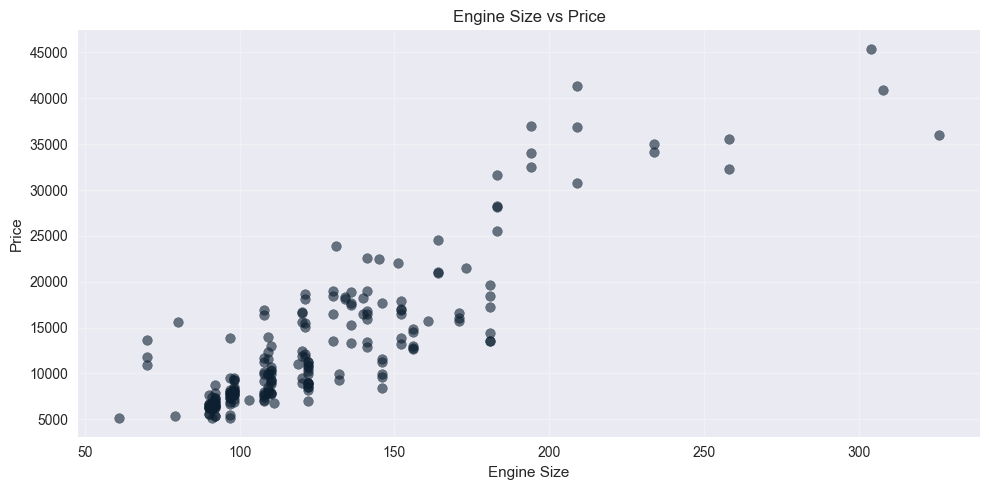

In [18]:
# Quick numeric conversion for plotting
df_plot = df_raw.copy()
for col in ['engine_size', 'price', 'horsepower', 'curb_weight']:
    df_plot[col] = pd.to_numeric(df_plot[col], errors='coerce') 
    """coerce will convert non-numeric values to NaN, which is useful for handling missing or invalid data."""

# ── TASK 1 ──────────────────────────────────────────────────────────────────
# Create a scatter plot of engine_size (x) vs price (y)
# Use: fig, ax = plt.subplots(figsize=(8, 5))
# Add title, x-label, y-label, and a grid (alpha=0.3)
# Set marker colour to '#2196F3', alpha=0.6
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))
"""fig, ax = plt.subplots(figsize=(10, 5)) creates a new figure and a set of subplots 
(in this case, just one subplot) with a specified size of 10 inches by 5 inches. 
The variable fig holds the reference to the entire figure, while ax is an AxesSubplot object
 that we can use to plot our data and customize the appearance of the plot."""
# YOUR CODE HERE

ax.scatter(
    df_plot['engine_size'],
    df_plot['price'],
    c="#0D2031",
    alpha=0.6
)

ax.set_title('Engine Size vs Price') # Sets the title of the plot to 'Engine Size vs Price'
ax.set_xlabel('Engine Size') # Sets the label for the x-axis to 'Engine Size'
ax.set_ylabel('Price') # Sets the label for the y-axis to 'Price'
ax.grid(alpha=0.3) # Adds a grid to the plot with a transparency level of 0.3, making it less prominent and allowing the data points to stand out more clearly

plt.tight_layout() # Adjusts the padding between and around subplots to prevent overlap
plt.show() # Displays the plot on the screen

# 📝 What pattern do you notice between engine size and price?
# ...

## Multi-Panel Layouts

`plt.subplots(rows, cols)` creates a grid of Axes objects.  
With a 2×2 grid, `axes` becomes a 2D array: `axes[0][0]`, `axes[0][1]`, `axes[1][0]`, `axes[1][1]`.

[[<Axes: > <Axes: >]
 [<Axes: > <Axes: >]]


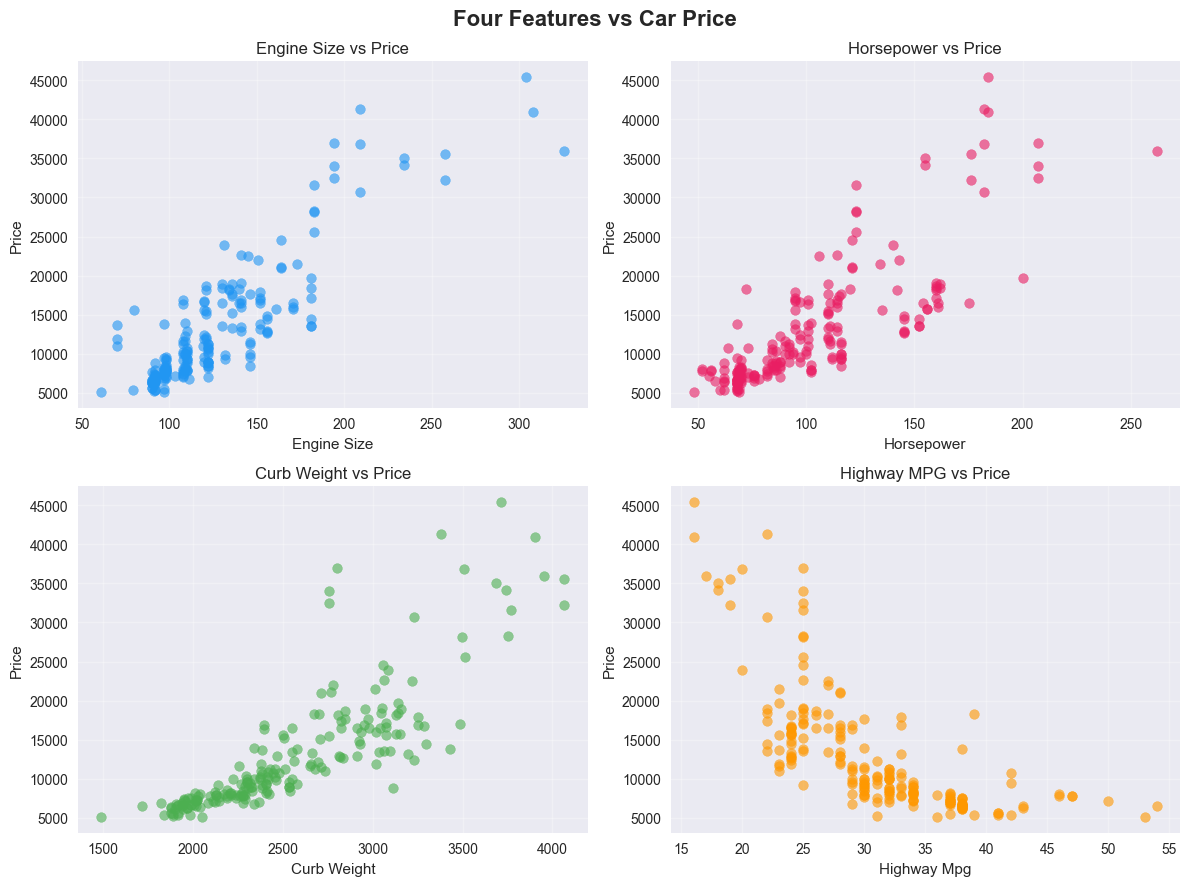

In [28]:
# ── TASK 2 ──────────────────────────────────────────────────────────────────
# Create a 2×2 subplot grid (figsize=(12, 9)) showing:
#   [0][0]  engine_size vs price      colour '#2196F3'
#   [0][1]  horsepower  vs price      colour '#E91E63'
#   [1][0]  curb_weight vs price      colour '#4CAF50'
#   [1][1]  highway_mpg vs price      colour '#FF9800'
# Each subplot needs a title, x-label, y-label, and grid(alpha=0.3)
# After plotting, save the figure as 'four_features_vs_price.png'
#   Use dpi=300 and bbox_inches='tight'
# ─────────────────────────────────────────────────────────────────────────────

from matplotlib.cbook import flatten


fig, axes = plt.subplots(2, 2, figsize=(12, 9))
print(axes)

# YOUR CODE HERE
scatter_config=[
    ('engine_size', 'price', '#2196F3', 'Engine Size vs Price'),
    ('horsepower', 'price', '#E91E63', 'Horsepower vs Price'),
    ('curb_weight', 'price', '#4CAF50', 'Curb Weight vs Price'),
    ('highway_mpg', 'price', '#FF9800', 'Highway MPG vs Price')
]

for ax, (x_col, y_col, color, title) in zip(axes.flatten(), scatter_config):
    ax.scatter(df_plot[x_col], df_plot[y_col], c=color, alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel(x_col.replace('_', ' ').title())
    ax.set_ylabel(y_col.replace('_', ' ').title())
    ax.grid(alpha=0.3)



plt.suptitle('Four Features vs Car Price', fontsize=16, fontweight='bold')
plt.tight_layout()

# Save — dpi=300 is print quality; bbox_inches='tight' removes whitespace padding
# YOUR CODE HERE (plt.savefig ...)

plt.show()

# 📝 Which feature shows the strongest relationship with price? Which the weakest?
# ...

---
# Part 2 — Seaborn for Statistical Visualisation

**Seaborn is built on top of Matplotlib** — every Seaborn chart is a Matplotlib figure underneath.  
This means all your `ax.set_title()`, `ax.grid()` etc. still work on Seaborn charts.

Seaborn adds: automatic confidence intervals, grouping by category, built-in colour palettes, and distribution overlays.

---
## 2A — Categorical Charts

In [29]:
# Clean dataset for seaborn charts
df_clean = df_raw.copy()
for col in ['price', 'horsepower', 'engine_size', 'curb_weight',
            'highway_mpg', 'city_mpg', 'wheel_base', 'length',
            'width', 'normalized_losses', 'bore', 'stroke', 'peak_rpm']:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
df_clean = df_clean.dropna(subset=['price'])
print(f'Clean dataset: {df_clean.shape}')

Clean dataset: (201, 26)


/var/folders/1j/qv6pdxz918j7rbrft68hxg_80000gn/T/ipykernel_13738/3667724954.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


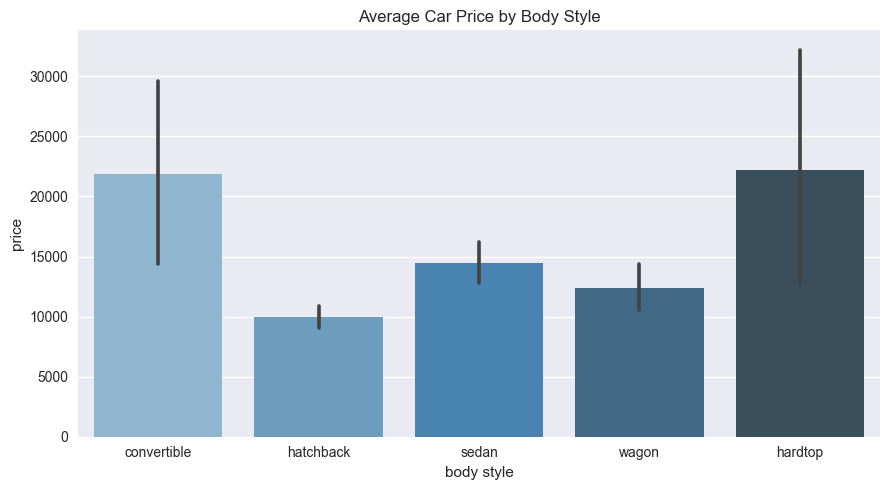

In [33]:
# ── TASK 3 — Bar Plot ────────────────────────────────────────────────────────
# Plot average price by body_style using sns.barplot
# Parameters to use: data, x, y, estimator='mean', palette='Blues_d'
# Add title: 'Average Car Price by Body Style'
# The thin error bars Seaborn draws automatically are 95% confidence intervals
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(9, 5))

# YOUR CODE HERE
sns.barplot(
    data=df_clean,
    x='body_style',
    y='price',
    estimator='mean',
    palette='Blues_d',
    ax=ax
)


plt.title('Average Car Price by Body Style') # Sets the title of the plot to 'Average Car Price by Body Style'
ax.set_xlabel('body style') # Sets the label for the x-axis to 'body style'
ax.set_ylabel('price') # Sets the label for the y-axis to 'price'
plt.tight_layout()
plt.show()

# 📝 Which body style is most expensive on average? Which is cheapest?
# ...

/var/folders/1j/qv6pdxz918j7rbrft68hxg_80000gn/T/ipykernel_13738/229431735.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


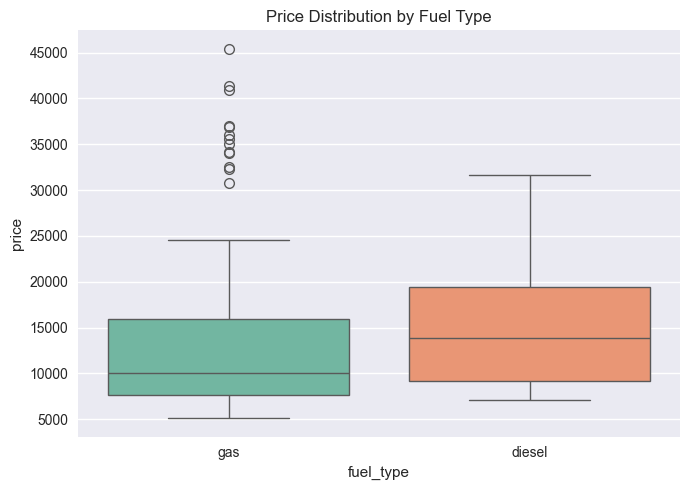

In [38]:
# Reading a box plot:
#
#   Whisker top  = Q3 + 1.5 × IQR
#   Box top      = Q3  (75th percentile)
#   Line inside  = Median (50th percentile)
#   Box bottom   = Q1  (25th percentile)
#   Whisker base = Q1 - 1.5 × IQR
#   Individual dots beyond whiskers = Outliers

# ── TASK 4 — Box Plot ────────────────────────────────────────────────────────
# Plot price distribution by fuel_type using sns.boxplot
# palette='Set2'
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 5))

# YOUR CODE HERE
sns.boxplot(
    data=df_clean,
    x='fuel_type',
    y='price',
    palette='Set2',
    ax=ax
)
plt.title('Price Distribution by Fuel Type') # Sets the title of the plot to 'Price Distribution by Fuel Type'
ax.set_xlabel('fuel type')
ax.set_ylabel('price')
plt.tight_layout()
plt.show()

# 📝 Which fuel type has a higher median price? Which has more outliers?
# ...

In [36]:
help(sns.boxplot)

Help on function boxplot in module seaborn.categorical:

boxplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    order=None,
    hue_order=None,
    orient=None,
    color=None,
    palette=None,
    saturation=0.75,
    fill=True,
    dodge='auto',
    width=0.8,
    gap=0,
    whis=1.5,
    linecolor='auto',
    linewidth=None,
    fliersize=None,
    hue_norm=None,
    native_scale=False,
    log_scale=None,
    formatter=None,
    legend='auto',
    ax=None,
    **kwargs
)
    Draw a box plot to show distributions with respect to categories.

    A box plot (or box-and-whisker plot) shows the distribution of quantitative
    data in a way that facilitates comparisons between variables or across
    levels of a categorical variable. The box shows the quartiles of the
    dataset while the whiskers extend to show the rest of the distribution,
    except for points that are determined to be "outliers" using a method
    that is a function of the inter-quartile range.


/var/folders/1j/qv6pdxz918j7rbrft68hxg_80000gn/T/ipykernel_13738/811194991.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/1j/qv6pdxz918j7rbrft68hxg_80000gn/T/ipykernel_13738/811194991.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


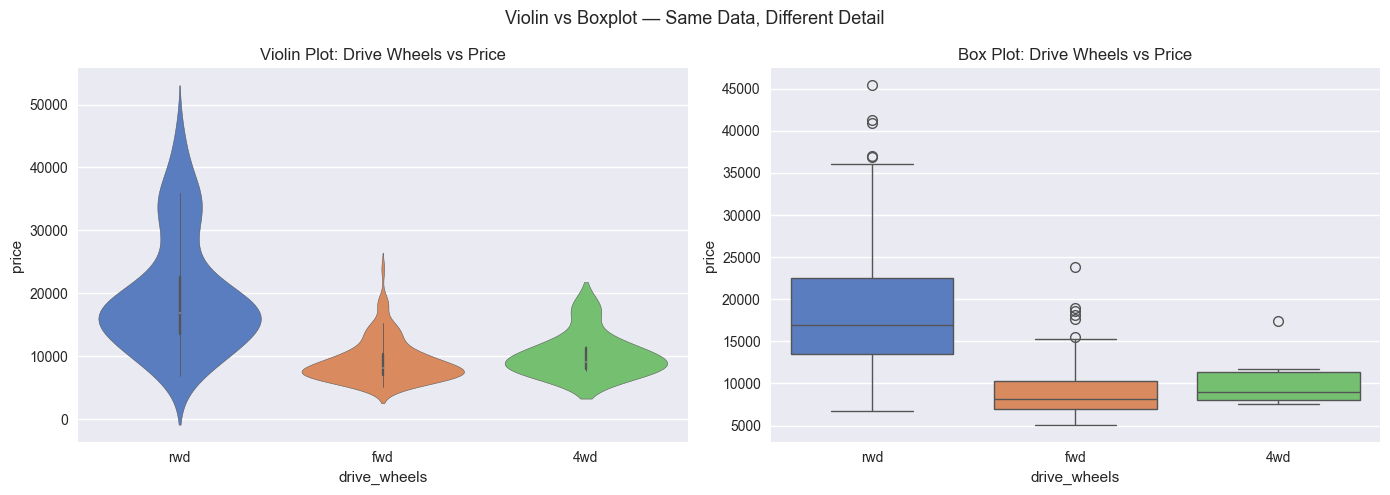

In [44]:
# ── TASK 5 — Violin vs Box ───────────────────────────────────────────────────
# Create a side-by-side comparison (1×2 subplots, figsize=(14,5))
# Left:  sns.violinplot  — drive_wheels vs price
# Right: sns.boxplot     — drive_wheels vs price  (same data)
# palette='muted' for both
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# YOUR CODE HERE
sns.violinplot(
    data=df_clean,
    x='drive_wheels',
    y='price',
    palette='muted',
    ax=axes[0]
)
axes[0].set_title('Violin Plot: Drive Wheels vs Price') # Sets the title of the left subplot to 'Violin Plot: Drive Wheels vs Price'
# axes[0].set_xlabel('drive wheels') # Sets the label for the x-axis of the left subplot to 'drive wheels'
# axes[0].set_ylabel('price') # Sets the label for the y-axis of the left subplot to 'price'
sns.boxplot(
    data=df_clean,
    x='drive_wheels',
    y='price',
    palette='muted',
    ax=axes[1]
)
axes[1].set_title('Box Plot: Drive Wheels vs Price') # Sets the title of the right subplot to 'Box Plot: Drive Wheels vs Price'
# axes[1].set_xlabel('drive wheels') # Sets the label for the x-axis of the right subplot to 'drive wheels'
# axes[1].set_ylabel('price') # Sets the label for the y-axis of the right subplot to 'price'
plt.suptitle('Violin vs Boxplot — Same Data, Different Detail', fontsize=13)
plt.tight_layout()
plt.show()

# 📝 What information is visible in the violin but hidden in the box?
# When would you choose each?
# ...

## 2B — Distribution Charts

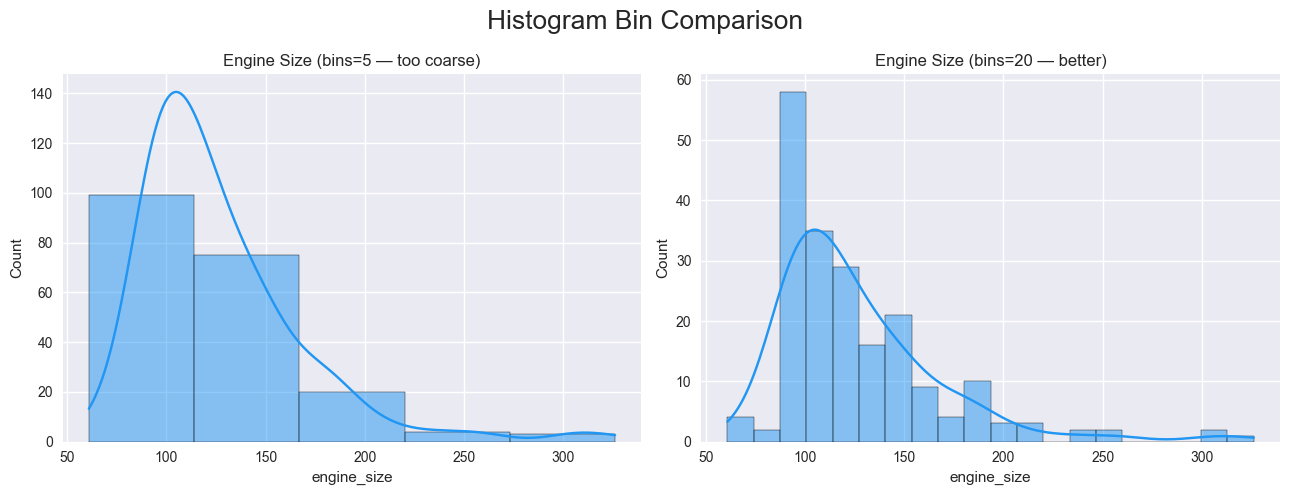

In [48]:
# ── TASK 6 — Histogram bin comparison ───────────────────────────────────────
# Create 1×2 subplots (figsize=(13,5))
# Left:  sns.histplot of engine_size, bins=5,  kde=True, colour '#2196F3'
# Right: sns.histplot of engine_size, bins=20, kde=True, colour '#2196F3'
# Title each: 'Engine Size (bins=5 — too coarse)' and 'Engine Size (bins=20 — better)'
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# YOUR CODE HERE
sns.histplot(
    data=df_clean,
    x='engine_size',
    bins=5,
    kde=True,
    color='#2196F3',
    ax=axes[0]
)
axes[0].set_title('Engine Size (bins=5 — too coarse)') # Sets the title of the left subplot to 'Engine Size (bins=5 — too coarse)'
sns.histplot(
    data=df_clean,
    x='engine_size',    
    bins=20,
    kde=True,
    color='#2196F3',
    ax=axes[1]      
)
axes[1].set_title('Engine Size (bins=20 — better)') # Sets the title of the right subplot to 'Engine Size (bins=20 — better)'
plt.suptitle('Histogram Bin Comparison', fontsize=19)
plt.tight_layout()
plt.show()

# 📝 Is engine_size left-skewed, right-skewed, or roughly symmetric?
# ...

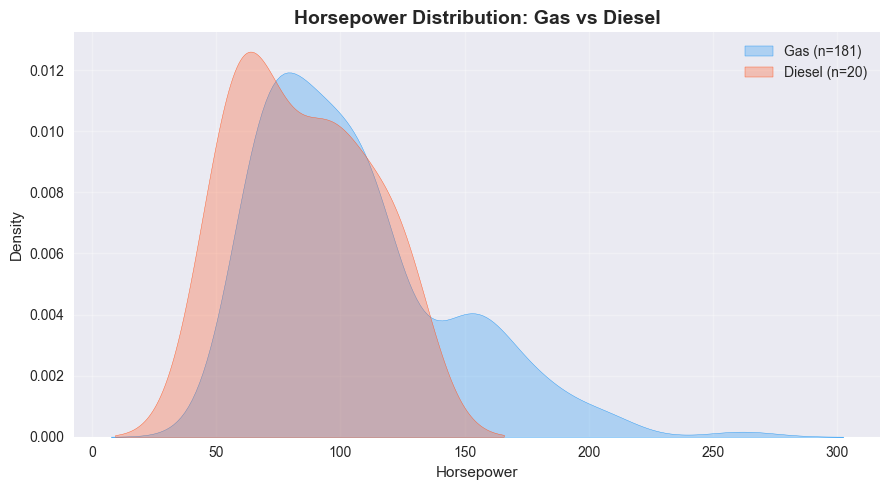

In [52]:
# ── TASK 7 — Overlapping KDE ─────────────────────────────────────────────────
# Plot horsepower KDE for gas cars AND diesel cars on the same axes
# Loop over fuel types: gas='#2196F3', diesel='#FF5722'
# Use fill=True, alpha=0.3 on each kdeplot
# Include a legend showing fuel type and sample size: e.g. 'Gas (n=184)'
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(9, 5))

# YOUR CODE HERE
for fuel in ['gas', 'diesel']:
    subset = df_clean[df_clean['fuel_type'] == fuel] # Creates a subset of the DataFrame df_clean that contains only the rows where the 'fuel_type' column matches the current fuel type in the loop (either 'gas' or 'diesel'). This allows us to plot the KDE for each fuel type separately.
    sns.kdeplot(
        data=subset,
        x='horsepower',
        # hue='fuel_type',
        fill=True,
        alpha=0.3,
        color='#2196F3' if fuel == 'gas' else '#FF5722',
        label=f'{fuel.capitalize()} (n={len(subset)})',
        ax=ax
    )

ax.set_title('Horsepower Distribution: Gas vs Diesel', fontsize=14, fontweight='bold')
ax.set_xlabel('Horsepower') 
ax.set_ylabel('Density')
ax.grid(alpha=0.3)
ax.legend() # Displays the legend on the plot, showing the labels for each fuel type with their corresponding colors and sample sizes
plt.tight_layout()
plt.show()

# 📝 Which fuel type has a wider horsepower range?
# ...

## 2C — Correlation Heatmap

                   symboling  normalized_losses  wheel_base    length  \
symboling           1.000000           0.528667   -0.535987 -0.365404   
normalized_losses   0.528667           1.000000   -0.074362  0.023220   
wheel_base         -0.535987          -0.074362    1.000000  0.876024   
length             -0.365404           0.023220    0.876024  1.000000   
width              -0.242423           0.105073    0.814507  0.857170   
height             -0.550160          -0.432335    0.590742  0.492063   
curb_weight        -0.233118           0.119893    0.782097  0.880665   
engine_size        -0.110581           0.167365    0.572027  0.685025   
bore               -0.144324          -0.036167    0.494884  0.610051   
stroke             -0.008245           0.065627    0.158502  0.124139   
compression_ratio  -0.182196          -0.132654    0.250313  0.159733   
horsepower          0.076038           0.295772    0.371621  0.580309   
peak_rpm            0.280635           0.264597   -

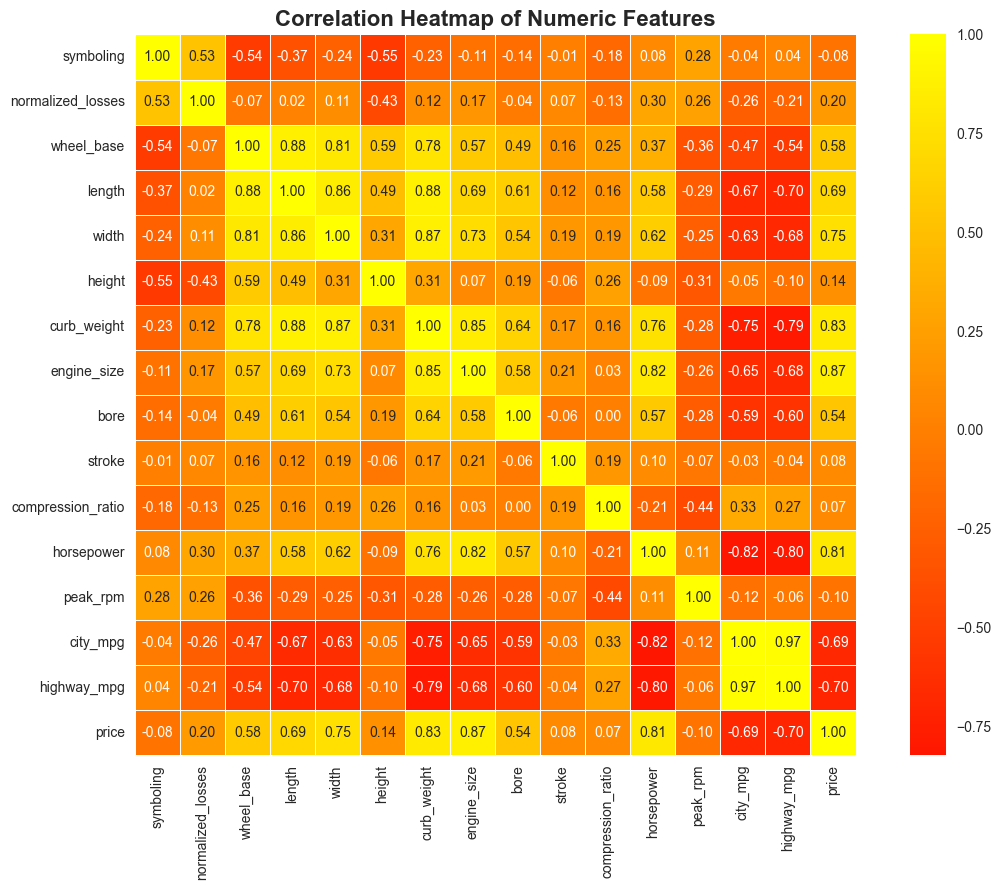

In [61]:
# ── TASK 8 — Correlation Heatmap ────────────────────────────────────────────
# 1. Compute the correlation matrix for all numeric columns in df_clean
#    Use: df_clean.select_dtypes(include='number').corr()
# 2. Plot it with sns.heatmap:
#    annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5
# 3. Use figsize=(12, 9)
# ─────────────────────────────────────────────────────────────────────────────

# YOUR CODE HERE
numeric_col=df_clean.select_dtypes(include='number').corr() # Computes the correlation matrix for all numeric columns in the DataFrame df_clean by selecting only the columns with numeric data types and applying the .corr() method to calculate the pairwise correlation coefficients between those columns.
correlation_matrix = df_clean.select_dtypes(include='number').corr()# Computes the correlation matrix for all numeric columns in the DataFrame df_clean by selecting only the columns with numeric data types and applying the .corr() method to calculate the pairwise correlation coefficients between those columns.
plt.figure(figsize=(12, 9))# Set the size of the figure to 12 inches by 9 inches to ensure the heatmap is large enough to be easily readable
print(correlation_matrix) # Print the correlation matrix to the console for reference
sns.heatmap(
    correlation_matrix,
    annot=True, # Annotates each cell in the heatmap with the correlation coefficient value, making it easier to interpret the strength and direction of the relationships between variables.
    fmt='.2f',# Formats the annotation text to display the correlation coefficients with two decimal places for better readability and precision.
    cmap='coolwarm',# Uses the 'coolwarm' colormap to visually differentiate between positive and negative correlations, with warmer colors indicating stronger positive correlations and cooler colors indicating stronger negative correlations.
    center=0,# Centers the colormap at 0, which means that the color representing a correlation of 0 will be neutral (often white or light gray), while positive and negative correlations will be colored according to the 'coolwarm' scheme.
    square=True,# Ensures that each cell in the heatmap is square-shaped, which can improve the visual appeal and readability of the heatmap by maintaining consistent aspect ratios for all cells.
    linewidths=0.5# Adds thin lines between the cells in the heatmap with a width of 0.5, which helps to visually separate the individual correlation values and makes it easier to distinguish between them.
)
plt.title('Correlation Heatmap of Numeric Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Find the top 3 features most correlated with 'price':
# 1. ...
# 2. ...
# 3. ...

In [64]:
# ── TASK 9 — Print top correlations with price ───────────────────────────────
# From the correlation matrix, sort features by |correlation| with 'price'
# Print the top 5 with direction (positive / negative)
# ─────────────────────────────────────────────────────────────────────────────

# YOUR CODE HERE
correlation_with_price = correlation_matrix['price'].drop('price').sort_values(key=abs, ascending=False) # Extracts the correlation coefficients for all features with respect to the 'price' column from the correlation matrix, while dropping the 'price' entry itself to focus on the relationships between 'price' and the other features.
correlation_with_price


engine_size          0.872335
curb_weight          0.834415
horsepower           0.810533
width                0.751265
highway_mpg         -0.704692
length               0.690628
city_mpg            -0.686571
wheel_base           0.584642
bore                 0.543436
normalized_losses    0.203254
height               0.135486
peak_rpm            -0.101649
symboling           -0.082391
stroke               0.082310
compression_ratio    0.071107
Name: price, dtype: float64

---
# Part 3 — Feature Types & the EDA Workflow

| Type | Description | Automobile Examples |
|------|-------------|---------------------|
| **Numerical continuous** | Any value in a range | price, engine_size, horsepower |
| **Numerical discrete** | Whole numbers | symboling, city_mpg, highway_mpg |
| **Categorical nominal** | No natural order | make, fuel_type, body_style |
| **Categorical ordinal** | Has a natural order | num_of_cylinders ← stored as words! |
| **Boolean** | Two states | aspiration (std/turbo), engine_location |

> ⚠️ `num_of_cylinders` looks like a number but is stored as words (`'four'`, `'six'` ...).  
> `df.dtypes` will show it as `object`. Sorting will be **alphabetical**, not numerical.

## The 6-Step EDA Workflow

Run every step. After each output, write a one-line interpretation as a comment.

In [68]:
# ── STEP 1 — Shape ──────────────────────────────────────────────────────────
# Print number of rows and columns
# Also calculate: if 4 values are missing, what % of the dataset is that?

# YOUR CODE HERE
df_raw.shape # Prints the shape of the DataFrame df_raw, which includes the number of rows and columns in the dataset. This information is useful for understanding the size of the dataset and for calculating the percentage of missing values if needed.
print(df_raw.isna().sum()) # Calculates the number of missing values (NaN) in each column of the DataFrame df_raw, which helps to identify which columns have missing data and how many missing values there are in each column. This information is crucial for understanding the extent of missing data in the dataset and for making informed decisions about how to handle it.
# 📝 Why does dataset size matter for missing values?
# ...

symboling             0
normalized_losses    41
make                  0
fuel_type             0
aspiration            0
num_of_doors          2
body_style            0
drive_wheels          0
engine_location       0
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_type           0
num_of_cylinders      0
engine_size           0
fuel_system           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 4
dtype: int64


In [70]:
# ── STEP 2 — Data Types ─────────────────────────────────────────────────────
# Print dtypes of all columns

# YOUR CODE HERE
print(df_raw.dtypes) # Prints the data types of all columns in the DataFrame df_raw, which helps to identify which columns are numeric, categorical, or of other types. This information is essential for understanding how to handle each column during data analysis and visualization, as different data types may require different processing techniques.

# 📝 Which columns SHOULD be numeric but show as 'object'? Why?
# ...

symboling              int64
normalized_losses    float64
make                     str
fuel_type                str
aspiration               str
num_of_doors             str
body_style               str
drive_wheels             str
engine_location          str
wheel_base           float64
length               float64
width                float64
height               float64
curb_weight            int64
engine_type              str
num_of_cylinders         str
engine_size            int64
fuel_system              str
bore                 float64
stroke               float64
compression_ratio    float64
horsepower           float64
peak_rpm             float64
city_mpg               int64
highway_mpg            int64
price                float64
dtype: object


In [83]:
# ── STEP 3 — Missing Values ─────────────────────────────────────────────────
# Create a DataFrame showing: Count of NaN and % of NaN per column
# Show only columns that have at least 1 missing value, sorted descending

# YOUR CODE HERE
nan=df_raw.isna().sum() # Calculates the number of missing values (NaN) in each column of the DataFrame df_raw, which helps to identify which columns have missing data and how many missing values there are in each column. This information is crucial for understanding the extent of missing data in the dataset and for making informed decisions about how to handle it.
# print(nan)
nan_pct=(nan/len(df_raw))*100 # Calculates the percentage of missing values for each column by dividing the count of NaN values by the total number of rows in the DataFrame (df_raw.shape[0]) and multiplying by 100 to express it as a percentage. This helps to understand the proportion of missing data in each column relative to the size of the dataset.
# print(nan_pct)

missing_summary_for_df=pd.DataFrame({
    'NaN Count': nan,
    'NaN %': nan_pct
})
if missing_summary_for_df['NaN Count'].sum() > 0:
   print("Columns with missing values:")
   print(missing_summary_for_df[missing_summary_for_df['NaN Count'] > 0].sort_values(by='NaN Count', ascending=False))
else:
   print("No missing values found in the dataset.")
# print(missing_summary_for_df)

# 📝 Which column has the most missing values? What % is that?
# ...

Columns with missing values:
                   NaN Count     NaN %
normalized_losses         41  20.00000
bore                       4   1.95122
stroke                     4   1.95122
price                      4   1.95122
num_of_doors               2   0.97561
horsepower                 2   0.97561
peak_rpm                   2   0.97561


In [90]:
# ── STEP 3b — Apply Cleaning Strategy ───────────────────────────────────────
# Rules:
#   price            → DROP rows (can't model without the target)
#   normalized_losses→ fill with MEDIAN  (41 missing — too many to drop)
#   bore, stroke, horsepower, peak_rpm → fill with column MEDIAN
#   num_of_doors     → fill with MODE

df = df_raw.copy()

# Convert to numeric first
for col in ['normalized_losses', 'bore', 'stroke', 'horsepower', 'peak_rpm', 'price']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# YOUR CODE HERE — apply the cleaning rules above
df=df.dropna(subset=['price']) # Drops rows from the DataFrame df where the 'price' column contains missing values (NaN), as these rows cannot be used for modeling since 'price' is the target variable.


for col in ['normalized_losses', 'bore', 'stroke', 'horsepower', 'peak_rpm']:
    median=df[col].median()
    df[col]=df[col].fillna(median) # Fills the missing values in the 'bore' column of the DataFrame df with the median value of that column, which is a common strategy for handling missing data in numeric columns to maintain the central tendency of the data without being affected by outliers.]
    print(f'Filled NaNs in {col} with median value: {median}')


mode=df['num_of_doors'].mode()
df['num_of_doors']=df['num_of_doors'].fillna(mode)
print(f'Filled NaNs in num_of_doors with mode value: {mode}') # Fills the missing values in the 'num_of_doors' column of the DataFrame df with the mode value of that column, which is a common strategy for handling missing data in categorical columns to maintain the most frequent category in the data.

print(f'Final shape: {df.shape}')
print(f'Remaining NaNs: {df.isnull().sum().sum()}')

Filled NaNs in normalized_losses with median value: 115.0
Filled NaNs in bore with median value: 3.31
Filled NaNs in stroke with median value: 3.29
Filled NaNs in horsepower with median value: 95.0
Filled NaNs in peak_rpm with median value: 5200.0
Filled NaNs in num_of_doors with mode value: 0    four
Name: num_of_doors, dtype: str
Final shape: (201, 26)
Remaining NaNs: 2


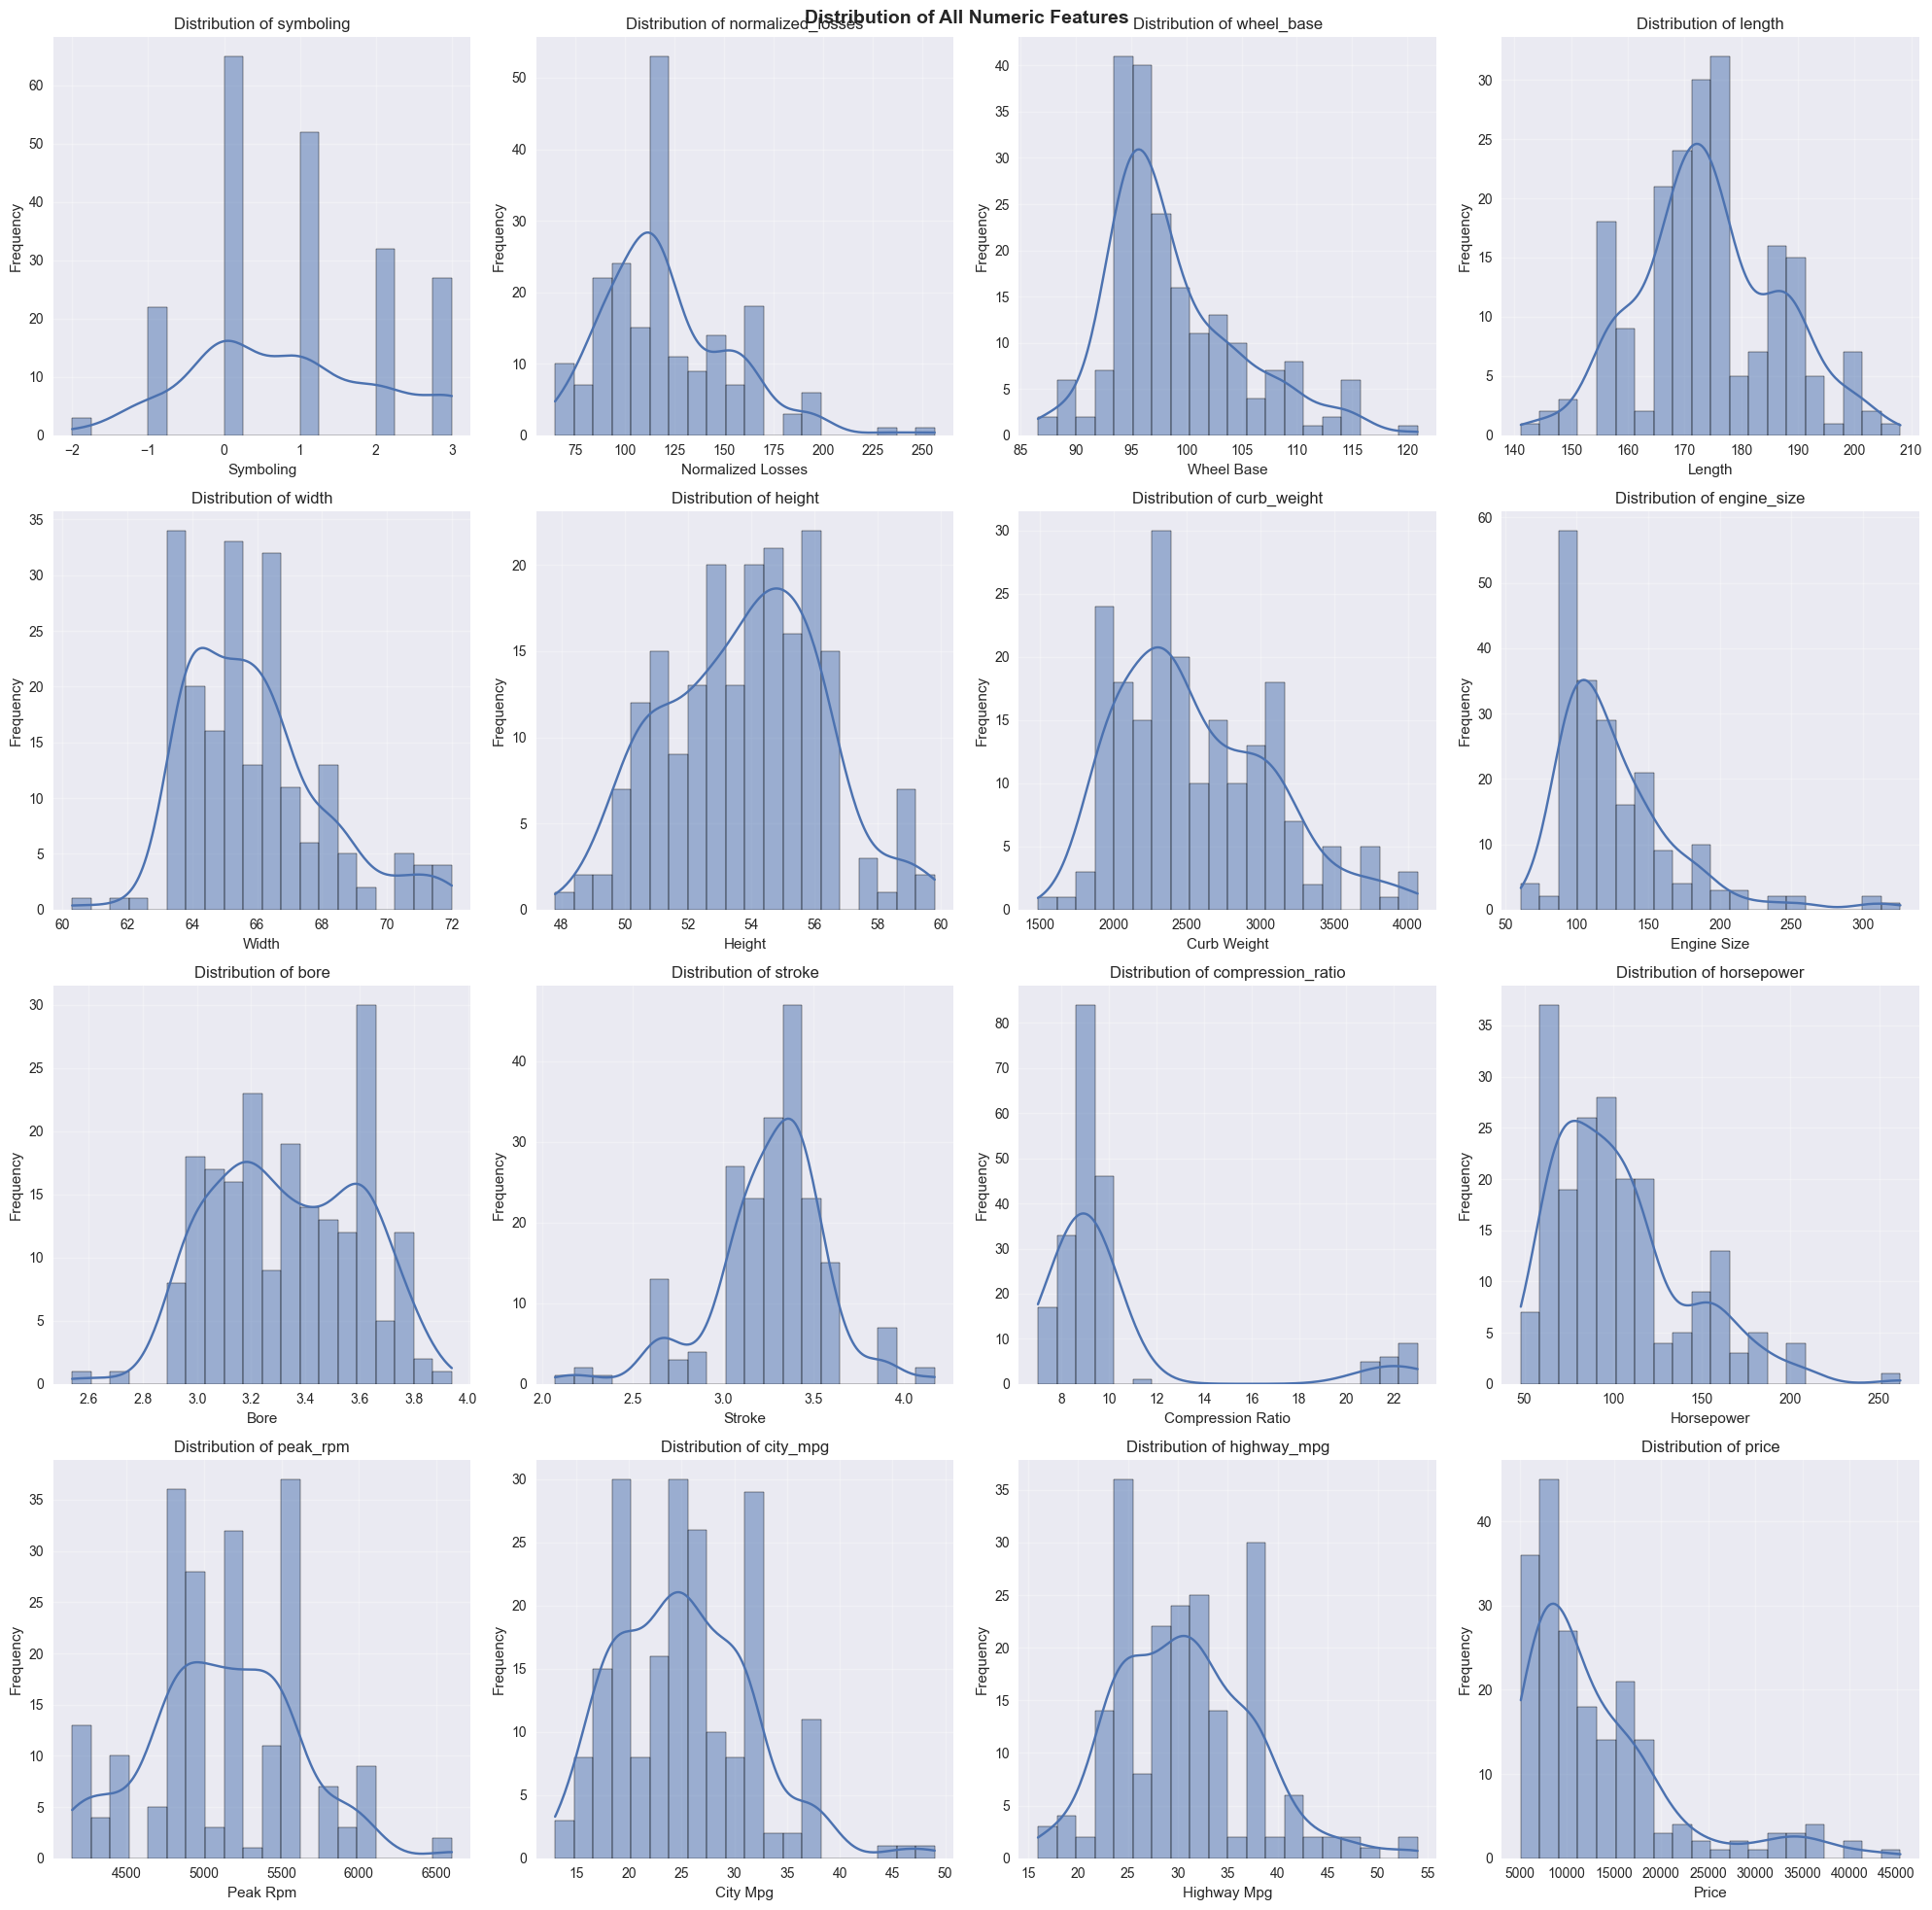

In [107]:
# ── STEP 4 — Distributions of All Numeric Features ──────────────────────────
# Loop through all numeric columns in df
# Plot a histplot (bins=20, kde=True) for each in a grid layout
# Hint: use axes.flatten() to convert the 2D grid to a 1D list
#       hide any unused panels with ax.set_visible(False)

num_cols = df.select_dtypes(include='number').columns.tolist()
n_cols_grid = 4
n_rows_grid = (len(num_cols) + n_cols_grid - 1) // n_cols_grid

fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(20, n_rows_grid * 5))
axes_flat = axes.flatten()

# YOUR CODE HERE
for i,col in enumerate(num_cols):
    sns.histplot(data=df,x=col,bins=20,kde=True,ax=axes_flat[i])
    axes_flat[i].set_title(f'Distribution of {col}') # Sets the title of each subplot to 'Distribution of {col}', where {col} is the name of the numeric column being plotted, providing context for the distribution being visualized in each histogram.
    axes_flat[i].set_xlabel(col.replace('_', ' ').title()) # Sets the x-axis label of each subplot to a more readable format by replacing underscores with spaces and capitalizing each word, making it easier to understand which feature is being plotted.
    axes_flat[i].set_ylabel('Frequency') # Sets the y-axis label of each subplot
    axes_flat[i].grid(alpha=0.3) # Adds a grid to each subplot with a transparency level of 0.3, which helps to improve the readability of the histogram by providing reference lines without overwhelming the visual representation of the data.
plt.suptitle('Distribution of All Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Which columns look right-skewed? Which look roughly normal?
# ...

In [99]:
# ── STEP 5 — Top Correlations with Price ────────────────────────────────────
# Print top 5 features by |correlation| with price, with direction labels

# YOUR CODE HERE
correlation_with_price = correlation_matrix['price'].drop('price').sort_values(key=abs, ascending=False) # Extracts the correlation coefficients for all features with respect to the 'price' column from the correlation matrix, while dropping the 'price' entry itself to focus on the relationships between 'price' and the other features.
correlation_with_price

engine_size          0.872335
curb_weight          0.834415
horsepower           0.810533
width                0.751265
highway_mpg         -0.704692
length               0.690628
city_mpg            -0.686571
wheel_base           0.584642
bore                 0.543436
normalized_losses    0.203254
height               0.135486
peak_rpm            -0.101649
symboling           -0.082391
stroke               0.082310
compression_ratio    0.071107
Name: price, dtype: float64

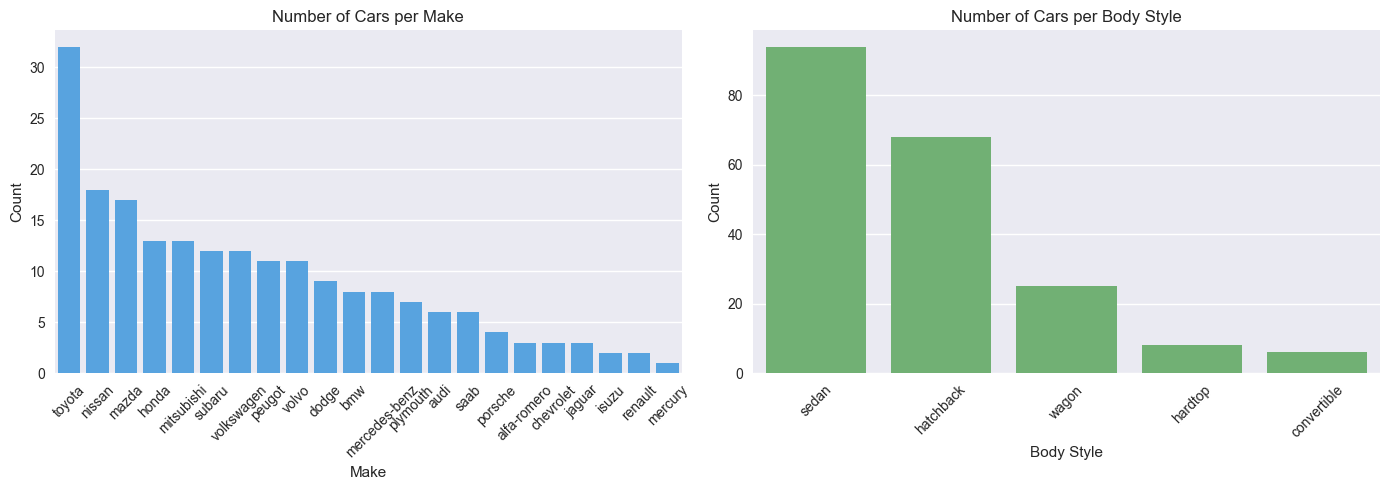

In [101]:
# ── STEP 6 — Class Balance ───────────────────────────────────────────────────
# Create 1×2 bar charts:
#   Left:  cars per make      (colour '#42A5F5')
#   Right: cars per body_style (colour '#66BB6A')
# Rotate x-labels for readability
# After the chart, print makes with fewer than 5 cars

from matplotlib.pyplot import ylabel


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# YOUR CODE HERE
make_counts = df['make'].value_counts() # Counts the number of occurrences of each unique value in the 'make' column of the DataFrame df, which helps to understand the distribution of car makes in the dataset and identify any class imbalance issues.
sns.barplot(
    x=make_counts.index,
    y=make_counts.values,
    color='#42A5F5',
    ax=axes[0]
)
axes[0].set_title('Number of Cars per Make') # Sets the title of the left subplot to 'Number of Cars per Make'
axes[0].set_xlabel('Make') # Sets the label for the x-axis of the left subplot to 'Make'
axes[0].set_ylabel('Count') # Sets the label for the y-axis of the left subplot to 'Count'
axes[0].tick_params(axis='x', rotation=45) # Rotates the x-axis labels of the left subplot by 45 degrees for better readability, especially when there are many categories          \
body_style_counts = df['body_style'].value_counts() # Counts the number of occurrences of each unique value in the 'body_style' column of the DataFrame df, which helps to understand the distribution of car body styles in the dataset and identify any class imbalance issues.
sns.barplot(
    x=body_style_counts.index,
    y=body_style_counts.values,
    color='#66BB6A',        
    ax=axes[1]
)
axes[1].set_title('Number of Cars per Body Style') # Sets the title of the right subplot to 'Number of Cars per Body Style'
axes[1].set_xlabel('Body Style') # Sets the label for the x-axis of the right subplot to 'Body Style'
axes[1].set_ylabel('Count') # Sets the label for the y-axis of the right subplot to 'Count'
axes[1].tick_params(axis='x', rotation=45) # Rotates the x-axis labels of the right subplot by 45 degrees for better readability, especially when there are many categories



plt.tight_layout()
plt.show()

# 📝 Why do makes with only 3–4 cars cause problems in groupby analysis and modelling?
# ...

---
# Part 4 — Correlation, Causation & Data Leakage

## ⚠️ The Most Important Lesson in EDA

> **High correlation does NOT mean one variable causes the other.**

`highway_mpg` has a strong negative correlation with `price` (r ≈ −0.70).  
Does better fuel economy make a car cheaper?

```
engine_size  ──→  price          (large engine → expensive)
     │
     └────────→  highway_mpg    (large engine → worse fuel economy)
```

`engine_size` is the **confounding variable**. Both `price` and `highway_mpg` are downstream of it.

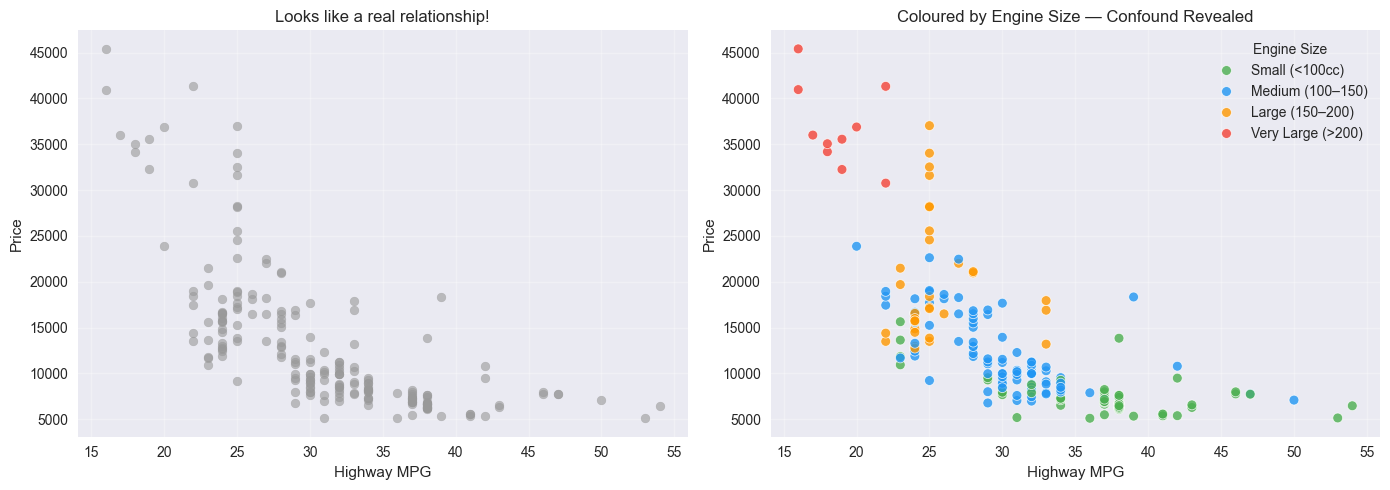

In [108]:
# ── TASK 10 — Confounding Variable Visualisation ────────────────────────────
# 1. Create an engine_size_bucket column using pd.cut:
#    bins=[0, 100, 150, 200, 400]
#    labels=['Small (<100cc)', 'Medium (100–150)', 'Large (150–200)', 'Very Large (>200)']
#
# 2. Create 1×2 subplots (figsize=(14,5)):
#    Left:  scatter highway_mpg vs price — all points grey (#999), title 'Looks like a real relationship!'
#    Right: same scatter but coloured by engine_size_bucket
#           palette = {'Small (<100cc)':'#4CAF50', 'Medium (100–150)':'#2196F3',
#                      'Large (150–200)':'#FF9800', 'Very Large (>200)':'#F44336'}
#           title 'Coloured by Engine Size — Confound Revealed'
# ─────────────────────────────────────────────────────────────────────────────

# YOUR CODE HERE
# create engine_size_bucket
bins = [0, 100, 150, 200, 400]
labels = ['Small (<100cc)', 'Medium (100–150)', 'Large (150–200)', 'Very Large (>200)']
df['engine_size_bucket'] = pd.cut(df['engine_size'], bins=bins, labels=labels, include_lowest=True)

# plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: grey scatter
axes[0].scatter(df['highway_mpg'], df['price'], c='#999999', alpha=0.6, s=40)
axes[0].set_title('Looks like a real relationship!')
axes[0].set_xlabel('Highway MPG')
axes[0].set_ylabel('Price')
axes[0].grid(alpha=0.3)

# right: coloured by engine size bucket
palette = {
    'Small (<100cc)': '#4CAF50',
    'Medium (100–150)': '#2196F3',
    'Large (150–200)': '#FF9800',
    'Very Large (>200)': '#F44336'
}
sns.scatterplot(data=df, x='highway_mpg', y='price', hue='engine_size_bucket',
                palette=palette, ax=axes[1], s=50, alpha=0.8)
axes[1].set_title('Coloured by Engine Size — Confound Revealed')
axes[1].set_xlabel('Highway MPG')
axes[1].set_ylabel('Price')
axes[1].grid(alpha=0.3)
axes[1].legend(title='Engine Size', loc='best')

plt.tight_layout()
plt.show()

# 📝 After seeing the right chart: does highway_mpg look like a useful
# independent predictor of price? Why or why not?
# ...

## Data Leakage

**Data leakage** = information that wouldn't be available at prediction time leaking into training data.  
Result: the model looks great in training → **fails completely in production**.

**Example — `normalized_losses`:** An insurance risk score partly calculated from claim costs, which correlate with repair costs, which correlate with car price. You would not have this score for a car whose price you are trying to predict.

| Leakage Type | Description |
|---|---|
| **Target proxy** | Feature derived from or correlated with target |
| **Future data** | Feature uses information from after the predicted event |
| **Label-derived** | Feature computed directly from the label |

In [109]:
# ── TASK 11 — Flag Potential Leakage ────────────────────────────────────────
# Review the columns below. Flag any that might cause leakage when predicting 'price'.
# For each, explain WHY in a comment.

print('All columns:')
for col in df.columns:
    print(f'  {col}')

# YOUR FLAGS:
# Column: ...  Reason: ...
# Column: ...  Reason: ...

All columns:
  symboling
  normalized_losses
  make
  fuel_type
  aspiration
  num_of_doors
  body_style
  drive_wheels
  engine_location
  wheel_base
  length
  width
  height
  curb_weight
  engine_type
  num_of_cylinders
  engine_size
  fuel_system
  bore
  stroke
  compression_ratio
  horsepower
  peak_rpm
  city_mpg
  highway_mpg
  price
  engine_size_bucket


In [110]:
df_raw['price'].max()

np.float64(45400.0)

---
# Part 5 — Outlier Detection & Final Report

## Why Outliers Matter
- **EDA:** A mean inflated by 3 Ferrari-level outliers doesn't represent the typical car
- **Modelling:** Outliers pull regression lines off course

## Method 1 — IQR
```
IQR = Q3 − Q1
Lower fence = Q1 − 1.5 × IQR
Upper fence = Q3 + 1.5 × IQR
```
Robust to skewed distributions — doesn't assume normality.

## Method 2 — Z-Score
```
z = (value − mean) / std    →    flag |z| > 3
```
Assumes approximate normality. Less robust on skewed data like `price`.

In [113]:
# ── TASK 12 — Write the IQR outlier detection function ──────────────────────
# Complete the function below.
# It should return: (outlier_df, lower_fence, upper_fence)

def detect_outliers_iqr(df: pd.DataFrame, col: str):
    """Return (outlier_rows_df, lower_fence, upper_fence) using IQR method."""
    # YOUR CODE HERE
    q3=df[col].quantile(0.75) # Calculates the third quartile (Q3) of the specified column in the DataFrame df, which represents the value below which 75% of the data falls.
    q1=df[col].quantile(0.25) # Calculates the first quartile (Q1) of the specified column in the DataFrame df, which represents the value below which 25% of the data falls.
    
    iqr=q3-q1 # Calculates the interquartile range (IQR) by subtracting the first quartile (Q1) from the third quartile (Q3). The IQR is a measure of statistical dispersion and is used to identify outliers in the data.
    
    lower_fence=q1-1.5*iqr # Calculates the lower fence for outlier detection using the IQR method. Any data point below this value is considered a potential outlier.
    upper_fence=q3+1.5*iqr # Calculates the upper fence for outlier detection using the IQR method. Any data point above this value is considered a potential outlier.
    
    outliers=df[(df[col]<lower_fence) | (df[col]>upper_fence)] # Creates a DataFrame containing the rows from the original DataFrame df where the values in the specified column are either below the lower fence or above the upper fence, effectively identifying the outliers based on the IQR method.
    
    return outliers, lower_fence, upper_fence # Returns a tuple containing the DataFrame of outlier rows, the lower fence, and the upper fence for the specified column.        

for col in ['price', 'horsepower', 'engine_size']:
    outliers, low, high = detect_outliers_iqr(df, col)
    print(f'{col}: fences=[{low:.1f}, {high:.1f}]  outliers={len(outliers)}')


# Test it on price, horsepower, engine_size
for col in ['price', 'horsepower', 'engine_size']:
    outliers, low, high = detect_outliers_iqr(df, col)
    print(f'{col}: fences=[{low:.1f}, {high:.1f}]  outliers={len(outliers)}')

price: fences=[-5312.5, 29587.5]  outliers=14
horsepower: fences=[1.0, 185.0]  outliers=5
engine_size: fences=[33.5, 205.5]  outliers=10
price: fences=[-5312.5, 29587.5]  outliers=14
horsepower: fences=[1.0, 185.0]  outliers=5
engine_size: fences=[33.5, 205.5]  outliers=10


In [118]:
# ── TASK 13 — Write the Z-Score outlier detection function ──────────────────
# Complete the function. Flag rows where |z| > threshold (default 3.0)
from scipy import stats
def detect_outliers_zscore(df: pd.DataFrame, col: str, threshold: float = 3.0) -> pd.DataFrame:
    """Return outlier rows using Z-score method."""
    z_scores = stats.zscore(df[col])
    return df[abs(z_scores) > threshold]


# Compare counts: IQR vs Z-score
print(f"{'Column':<15} {'IQR':>6} {'Z-Score':>9}")
print('-' * 32)
for col in ['price', 'horsepower', 'engine_size']:
    n_iqr = len(detect_outliers_iqr(df, col)[0])
    n_z   = len(detect_outliers_zscore(df, col))
    print(f'{col:<15} {n_iqr:>6} {n_z:>9}')

# 📝 Which method flags more outliers? Why might they disagree on skewed data?
# ...

Column             IQR   Z-Score
--------------------------------
price               14         4
horsepower           5         1
engine_size         10         5


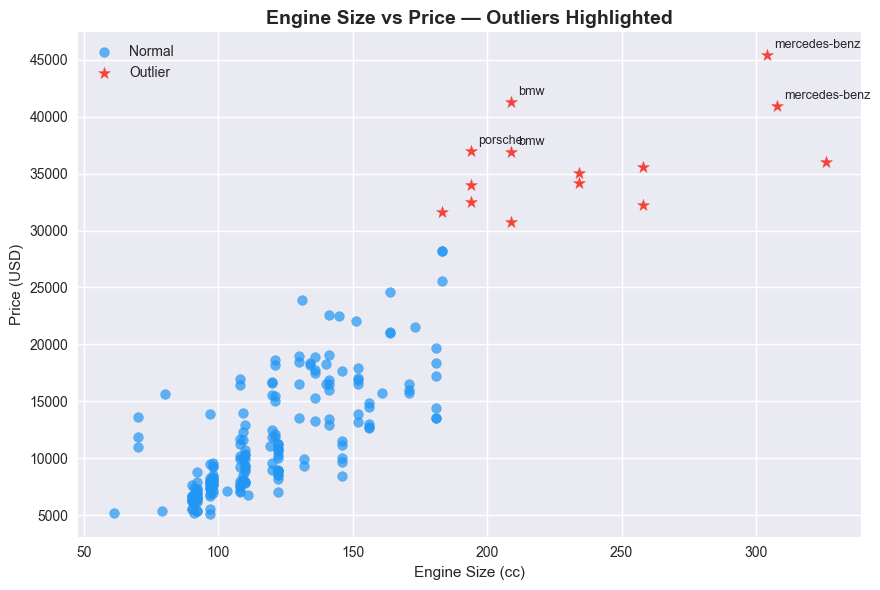


Makes in outlier group:
              make   body_style  engine_size    price
74   mercedes-benz      hardtop          304  45400.0
16             bmw        sedan          209  41315.0
73   mercedes-benz        sedan          308  40960.0
128        porsche  convertible          194  37028.0
17             bmw        sedan          209  36880.0
49          jaguar        sedan          326  36000.0
48          jaguar        sedan          258  35550.0
72   mercedes-benz  convertible          234  35056.0
71   mercedes-benz        sedan          234  34184.0
127        porsche      hardtop          194  34028.0
126        porsche      hardtop          194  32528.0
47          jaguar        sedan          258  32250.0
70   mercedes-benz        sedan          183  31600.0
15             bmw        sedan          209  30760.0


In [120]:
# ── TASK 14 — Visualise Outliers ─────────────────────────────────────────────
# Scatter plot: engine_size (x) vs price (y)
# Normal points: blue (#2196F3), s=50
# Outlier points (IQR on price): red (#F44336), s=80, marker='*'
# Annotate the top 5 highest-price outliers with their 'make'
#   Use ax.annotate(make, (engine_size, price), textcoords='offset points', xytext=(5,5))

outlier_df, _, _ = detect_outliers_iqr(df, 'price')
normal_df = df[~df.index.isin(outlier_df.index)]

fig, ax = plt.subplots(figsize=(9, 6))

# YOUR CODE HERE


ax.set_title('Engine Size vs Price — Outliers Highlighted', fontsize=14, fontweight='bold')
ax.set_xlabel('Engine Size (cc)')
ax.set_ylabel('Price (USD)')
ax.scatter(
    normal_df['engine_size'],
    normal_df['price'],
    c='#2196F3',
    s=50,
    alpha=0.7,
    label='Normal'
)

ax.scatter(
    outlier_df['engine_size'],
    outlier_df['price'],
    c='#F44336',
    s=80,
    marker='*',
    label='Outlier'
)

for _, row in outlier_df.sort_values('price', ascending=False).head(5).iterrows():
    ax.annotate(
        row['make'],
        (row['engine_size'], row['price']),
        textcoords='offset points',
        xytext=(5, 5),
        fontsize=9
    )
ax.legend()
plt.tight_layout()
plt.show()

print('\nMakes in outlier group:')
print(outlier_df[['make', 'body_style', 'engine_size', 'price']].sort_values('price', ascending=False))

In [121]:
# ── TASK 15 — Complete the Outlier Report ────────────────────────────────────
# Fill in the 'Error or Genuine' and 'Recommended Action' columns
# based on the scatter plot and the makes you saw above

report = pd.DataFrame({
    'Column':               ['price', 'horsepower', 'engine_size'],
    'N Outliers (IQR)':     [None, None, None],   # fill programmatically
    'N Outliers (Z)':       [None, None, None],   # fill programmatically
    'Error or Genuine':     ['???', '???', '???'], # YOUR ASSESSMENT
    'Recommended Action':   ['???', '???', '???']  # YOUR RECOMMENDATION
})

for i, col in enumerate(['price', 'horsepower', 'engine_size']):
    report.at[i, 'N Outliers (IQR)'] = len(detect_outliers_iqr(df, col)[0])
    report.at[i, 'N Outliers (Z)']   = len(detect_outliers_zscore(df, col))

print('=== OUTLIER REPORT ===')
print(report.to_string(index=False))

=== OUTLIER REPORT ===
     Column N Outliers (IQR) N Outliers (Z) Error or Genuine Recommended Action
      price               14              4              ???                ???
 horsepower                5              1              ???                ???
engine_size               10              5              ???                ???


---
# 📝 Day 4 Summary

| Concept | Key Takeaway |
|---------|-------------|
| **Figure vs Axes** | Figure = canvas. Axes = plot area. All real work on the Axes. |
| **Seaborn** | Built on Matplotlib. Handles statistics and grouping automatically. |
| **Feature types** | Continuous / Discrete / Nominal / Ordinal / Boolean — affects every decision. |
| **EDA workflow** | Shape → dtypes → nulls → distributions → correlations → class balance. |
| **Correlation ≠ Causation** | Look for confounding variables before drawing conclusions. |
| **Data leakage** | If a feature uses info unavailable at prediction time — drop it. |
| **Outlier removal** | Only drop data errors. Legitimate rare values carry real information. |

---
# 🏠 Assignment

1. **Confounding hunt:** Pick any two features with |r| > 0.6 (excluding price). Argue whether their correlation is causal or confounded by a third variable.

2. **Leakage flag:** Is `symboling` safe to use as a feature when predicting price? Write 3–5 sentences justifying your answer.

3. **Ordinal mapping:** `num_of_cylinders` stores numbers as words. Write code to map it to integers (`'two'→2`, `'three'→3`, ..., `'twelve'→12`). Then plot average price by cylinder count.

4. **Bonus:** Add `compression_ratio` vs `price` as a 5th panel to your Task 2 grid. Does it show a strong relationship?

In [122]:
df_clean.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [125]:
mean_of_price=df['price'].mean()
print(f'The mean price of the car is: {mean_of_price}')

mean_of_horsepower=df['horsepower'].mean()
print(f'The mean horsepower of the car is: {mean_of_horsepower}')

The mean price of the car is: 13207.129353233831
The mean horsepower of the car is: 103.31343283582089


In [129]:
for col in df_clean.select_dtypes(include='number').columns:
    mean_value=df_clean[col].abs().mean()
    print(f'The mean value of {col} is: {mean_value}')

The mean value of symboling is: 1.1194029850746268
The mean value of normalized_losses is: 122.0
The mean value of wheel_base is: 98.79701492537313
The mean value of length is: 174.20099502487562
The mean value of width is: 65.88905472636816
The mean value of height is: 53.766666666666666
The mean value of curb_weight is: 2555.6666666666665
The mean value of engine_size is: 126.87562189054727
The mean value of bore is: 3.330710659898477
The mean value of stroke is: 3.256903553299492
The mean value of compression_ratio is: 10.164278606965174
The mean value of horsepower is: 103.39698492462311
The mean value of peak_rpm is: 5117.587939698493
The mean value of city_mpg is: 25.17910447761194
The mean value of highway_mpg is: 30.686567164179106
The mean value of price is: 13207.129353233831


1. CONFOUNDING HUNT: curb_weight vs engine_size
Correlation: 0.849

Conclusion: CAUSAL relationship
Reason: Larger engines require heavier structural components.

2. LEAKAGE FLAG: Is 'symboling' safe to use?

ASSESSMENT: YES, symboling is SAFE to use.

JUSTIFICATION:
- Symboling is an insurance risk rating assigned BEFORE a car is sold.
- It reflects manufacturer characteristics (brand reputation, safety), not derived from price.
- It would be available at prediction time (known when valuing a new model).
- Unlike normalized_losses (which uses claims data), symboling is pre-determined.
- No data leakage risk: it's independent of the target variable.

3. ORDINAL MAPPING: num_of_cylinders to integers


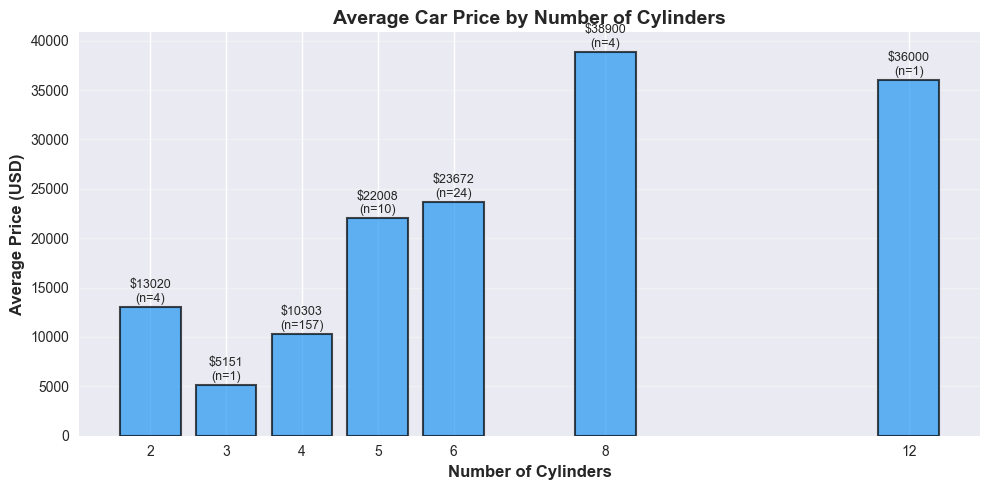


Cylinder counts and average prices:
 num_of_cylinders_int         mean  count
                    2 13020.000000      4
                    3  5151.000000      1
                    4 10303.197452    157
                    5 22007.600000     10
                    6 23671.833333     24
                    8 38900.000000      4
                   12 36000.000000      1

4. BONUS: 5-panel grid with compression_ratio


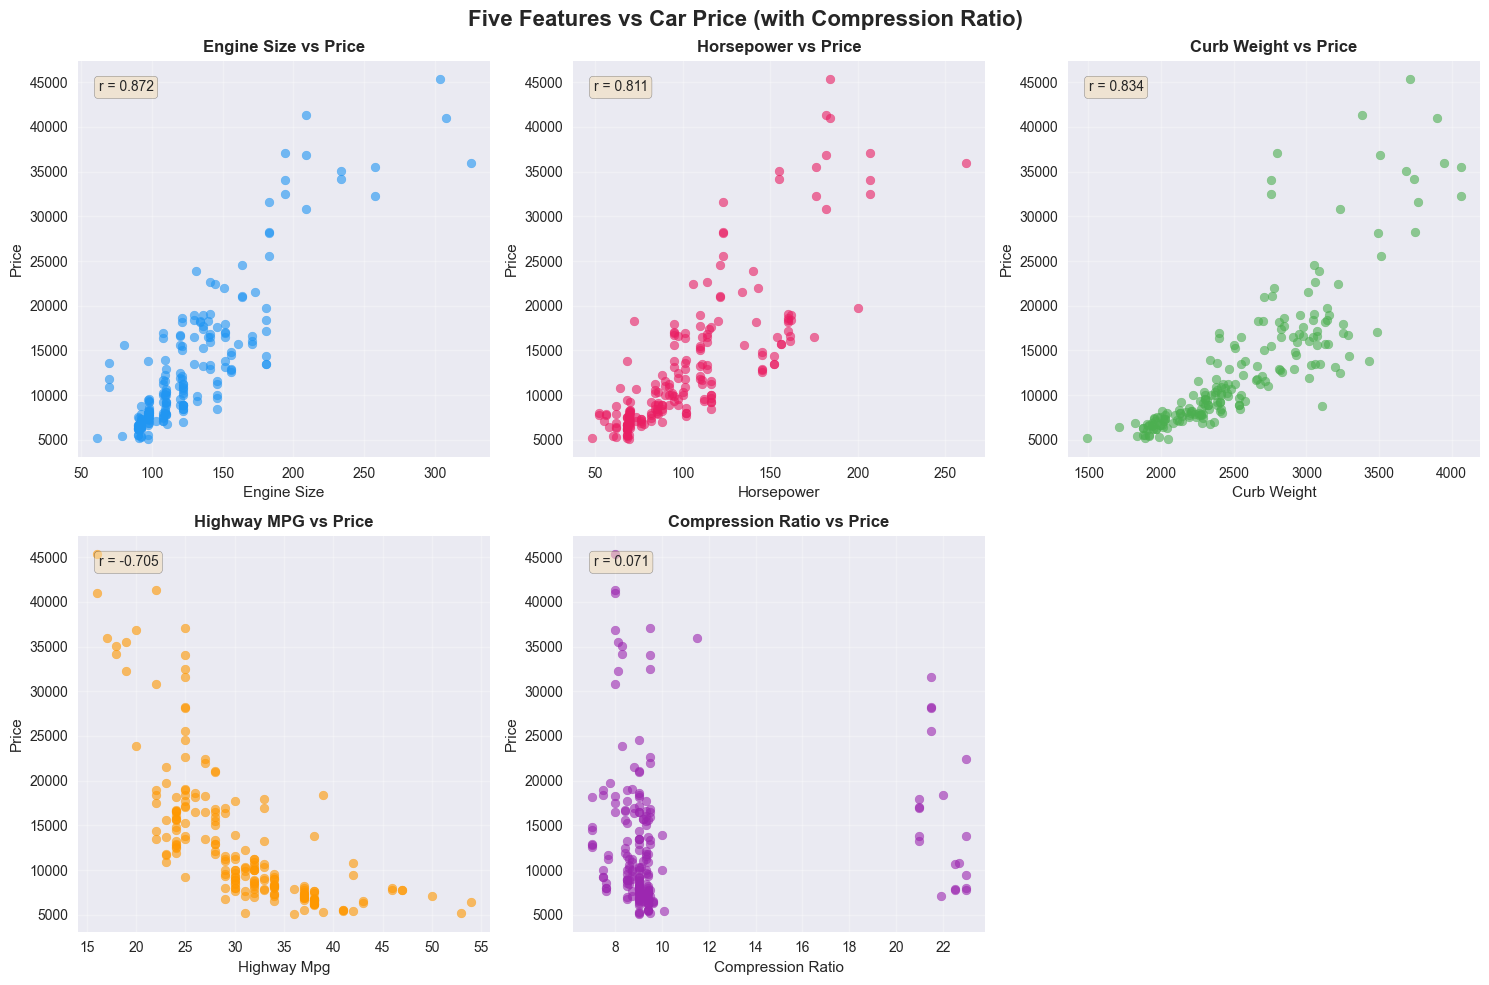


Compression Ratio Analysis:
Correlation with price: 0.071

Conclusion: Compression ratio shows a WEAK relationship with price (|r|=0.071).
This feature is less predictive than engine_size, horsepower, or curb_weight.


In [ ]:
# Assignment Solutions

# 1. CONFOUNDING HUNT
# Features with |r| > 0.6 (excluding price): curb_weight & engine_size (r=0.849)
# Argument: This correlation is CAUSAL, not confounded.
# Reason: Larger engines require stronger/heavier engine blocks and support structures.
# Engine size physically determines curb weight through engineering constraints.
# No third variable confounds this relationship.

print("=" * 70)
print("1. CONFOUNDING HUNT: curb_weight vs engine_size")
print("=" * 70)
print(f"Correlation: {correlation_matrix.loc['curb_weight', 'engine_size']:.3f}")
print("\nConclusion: CAUSAL relationship")
print("Reason: Larger engines require heavier structural components.\n")


# 2. LEAKAGE FLAG: symboling
print("=" * 70)
print("2. LEAKAGE FLAG: Is 'symboling' safe to use?")
print("=" * 70)
print("""
ASSESSMENT: YES, symboling is SAFE to use.

JUSTIFICATION:
- Symboling is an insurance risk rating assigned BEFORE a car is sold.
- It reflects manufacturer characteristics (brand reputation, safety), not derived from price.
- It would be available at prediction time (known when valuing a new model).
- Unlike normalized_losses (which uses claims data), symboling is pre-determined.
- No data leakage risk: it's independent of the target variable.
""")


# 3. ORDINAL MAPPING: num_of_cylinders
print("=" * 70)
print("3. ORDINAL MAPPING: num_of_cylinders to integers")
print("=" * 70)

cylinder_mapping = {
    'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6,
    'eight': 8, 'twelve': 12
}

df['num_of_cylinders_int'] = df['num_of_cylinders'].map(cylinder_mapping)

# Plot average price by cylinder count
fig, ax = plt.subplots(figsize=(10, 5))

cylinder_price = df.groupby('num_of_cylinders_int')['price'].agg(['mean', 'count']).reset_index()
cylinder_price = cylinder_price.sort_values('num_of_cylinders_int')

ax.bar(
    cylinder_price['num_of_cylinders_int'],
    cylinder_price['mean'],
    color='#2196F3',
    alpha=0.7,
    edgecolor='black',
    linewidth=1.5
)

ax.set_xlabel('Number of Cylinders', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Price (USD)', fontsize=12, fontweight='bold')
ax.set_title('Average Car Price by Number of Cylinders', fontsize=14, fontweight='bold')
ax.set_xticks(cylinder_price['num_of_cylinders_int'])
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for idx, row in cylinder_price.iterrows():
    ax.text(row['num_of_cylinders_int'], row['mean'] + 500,
            f"${row['mean']:.0f}\n(n={int(row['count'])})",
            ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print("\nCylinder counts and average prices:")
print(cylinder_price.to_string(index=False))


# 4. BONUS: Add compression_ratio to Task 2 grid (5th panel)
print("\n" + "=" * 70)
print("4. BONUS: 5-panel grid with compression_ratio")
print("=" * 70)

# Extend to 2 rows with 3 columns (6 panels total, 5 used)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes_flat = axes.flatten()

scatter_config_extended = [
    ('engine_size', 'price', '#2196F3', 'Engine Size vs Price'),
    ('horsepower', 'price', '#E91E63', 'Horsepower vs Price'),
    ('curb_weight', 'price', '#4CAF50', 'Curb Weight vs Price'),
    ('highway_mpg', 'price', '#FF9800', 'Highway MPG vs Price'),
    ('compression_ratio', 'price', '#9C27B0', 'Compression Ratio vs Price')
]

for ax, (x_col, y_col, color, title) in zip(axes_flat[:5], scatter_config_extended):
    ax.scatter(df[x_col], df[y_col], c=color, alpha=0.6, s=40)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(x_col.replace('_', ' ').title())
    ax.set_ylabel('Price')
    ax.grid(alpha=0.3)
    
    # Calculate and display correlation
    corr = df[[x_col, y_col]].corr().iloc[0, 1]
    ax.text(0.05, 0.95, f'r = {corr:.3f}',
            transform=ax.transAxes, fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Hide the 6th (unused) panel
axes_flat[5].set_visible(False)

plt.suptitle('Five Features vs Car Price (with Compression Ratio)', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('five_features_vs_price.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nCompression Ratio Analysis:")
corr_cr = df[['compression_ratio', 'price']].corr().iloc[0, 1]
print(f"Correlation with price: {corr_cr:.3f}")
print(f"\nConclusion: Compression ratio shows a WEAK relationship with price (|r|={abs(corr_cr):.3f}).")
print("This feature is less predictive than engine_size, horsepower, or curb_weight.")

In [132]:
df_clean.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [131]:
df_raw.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0
